LLaVa is an exciting new multimodal LLM which extends large language models like LLaMa with visual inputs.

For multimodal LLMs, one typically takes a pre-trained/fine-tuned LLM and additionally conditions it on image features. In case of LLaVa, the image features come from a pre-trained CLIP's vision encoder. To match the dimension of the image features with those of the text features, one applies a projection module, which could be a simple linear projection (like the original LLaVa), or more sophisticated like a two-layer MLP (used in LLaVa 1.5).

In [1]:
!pip install --upgrade -q accelerate bitsandbytes

In [ ]:
!pip install git+https://github.com/huggingface/transformers.git

  Cloning https://github.com/huggingface/transformers.git to /tmp/pip-req-build-011nopr8
  Running command git clone --filter=blob:none --quiet https://github.com/huggingface/transformers.git /tmp/pip-req-build-011nopr8
  Resolved https://github.com/huggingface/transformers.git to commit 95bafdcccfffe17ec383999fc39273867b11385e
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for transformers: filename=transformers-5.21.0.dev0-py3-none-any.whl size=14293640 sha256=54e48ae4911a7a4fbf5314a88ce4766d05393d4f0d6ef1a9173b18460d80d026
  Stored in directory: /tmp/pip-ephem-wheel-cache-sxkhuwkp/wheels/90/86/bb/8ad35b428289429952d8316d30f64abedae0ab2fcee0f4f46f
Successfully built transformers
  Attempting uninstall: transformers
    Found existing installation: transformers 5.20.2
    Uninstalling transformers-5.20.2:
      Successfully uninstalled transformers-5.20.2


Next, we load a model and corresponding processor from the hub. We specify device_map="auto" in order to automatically place the model on the available GPUs/CPUs

In [ ]:
from transformers import AutoProcessor, LlavaForConditionalGeneration
from transformers import BitsAndBytesConfig
import torch

quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.float16
)


model_id = "llava-hf/llava-1.5-7b-hf"

processor = AutoProcessor.from_pretrained(model_id)
model = LlavaForConditionalGeneration.from_pretrained(model_id, quantization_config=quantization_config, device_map="auto")

processor_config.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/701 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/674 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/505 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/950 [00:00<?, ?B/s]

...

model.safetensors.index.json:   0%|          | 0.00/70.1k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/686 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/141 [00:00<?, ?B/s]

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


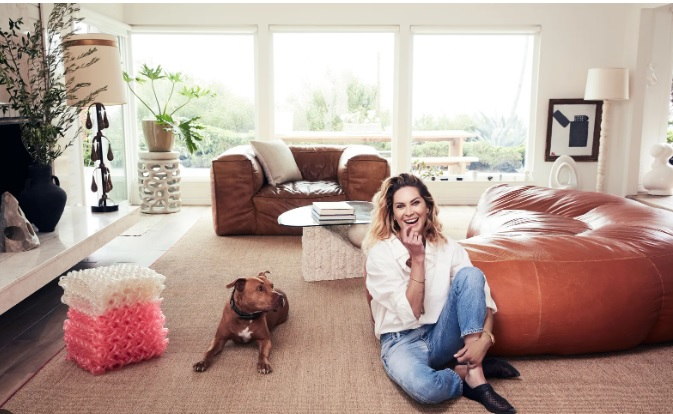

In [ ]:
from PIL import Image
import os

image_path = "/content/drive/MyDrive/DL/person_living_room.jpg"

if not os.path.exists(image_path):
    raise FileNotFoundError(f"Image not found: {image_path}")

image = Image.open(image_path).convert("RGB")
display(image)

In [ ]:
prompt = "What do you see in the image?"

inputs = processor(
    text=prompt,
    images=image,
    return_tensors="pt"
)

inputs = {
    k: v.to("cuda") if hasattr(v, "to") else v
    for k, v in inputs.items()
}

for k, v in inputs.items():
    if hasattr(v, "shape"):
        print(k, v.shape)

input_ids torch.Size([1, 9])
attention_mask torch.Size([1, 9])
pixel_values torch.Size([1, 3, 336, 336])


Finally, we simply let the model predict the next tokens given the images + prompt. Of course one can adjust all the generation parameters. By default, greedy decoding is used.

In [ ]:
from PIL import Image
import textwrap
import torch

image_path = "/content/drive/MyDrive/DL/person_living_room.jpg"
image = Image.open(image_path).convert("RGB")

prompt = "USER: <image>\nWhat do you see in the image?\nASSISTANT:"

inputs = processor(
    text=prompt,
    images=image,
    return_tensors="pt"
)

device = next(model.parameters()).device
inputs = {
    k: v.to(device) if isinstance(v, torch.Tensor) else v
    for k, v in inputs.items()
}

generated_text = processor.batch_decode(
    output,
    skip_special_tokens=True
)

for text in generated_text:
    answer = text.split("ASSISTANT:")[-1].strip()
    print("\nVLM Answer:\n")
    print(textwrap.fill(answer, width=80))


VLM Answer:

The image features a woman sitting on the floor in a living room, accompanied by
her dog. The woman is wearing a white shirt and appears to be enjoying her time
with her pet. The living room is furnished with a couch, a chair, and a dining
table. There are also several books scattered around the room, adding to the
cozy atmosphere.
